In [1]:
import pandas as pd

df = pd.read_csv("HospitalOPD-noname.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Number of rows: 62422
Number of columns: 25

Column names:
['record_no', 'patient_id', 'Unnamed: 2', 'appointment_id', 'appointment_start_datetime', 'prescription_doctor_id', 'prescription_doctor_name', 'prescription_order_id', 'prescription_start_datetime', 'prescription_end_datetime', 'lab_id', 'lab_name', 'lab_start_datetime', 'lab_end_datetime', 'imaging_request_id', 'imaging_result_id', 'imaging_name', 'imaging_start_datetime', 'imaging_end_datetime', 'pharmacy_sale_line_id', 'medicine_name', 'pharmacy_start_datetime', 'pharmacy_end_datetime', 'flow_code', 'flow_name']


,record_no,patient_id,Unnamed: 2,appointment_id,appointment_start_datetime,prescription_doctor_id,prescription_doctor_name,prescription_order_id,prescription_start_datetime,prescription_end_datetime,...,imaging_result_id,imaging_name,imaging_start_datetime,imaging_end_datetime,pharmacy_sale_line_id,medicine_name,pharmacy_start_datetime,pharmacy_end_datetime,flow_code,flow_name
0,1,10,NaN,445911,3/30/2026 5:36,225,Admin,106357,3/30/2026 5:38,3/30/2026 6:48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
1,2,57,NaN,335085,10/14/2025 5:23,193,Dr. Abrar Ahmed Bhatti,43515,10/14/2025 5:39,10/14/2025 5:53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
2,3,57,NaN,335085,10/14/2025 5:23,193,Dr. Abrar Ahmed Bhatti,43541,10/14/2025 6:11,10/14/2025 6:24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
3,4,60,NaN,322358,9/25/2025 13:36,195,Dr. Anique Ahmed,34654,9/25/2025 13:50,9/25/2025 13:51,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
4,5,72,NaN,337714,10/17/2025 6:40,202,Dr. Mehreen Batool Bokhari,45263,10/17/2025 6:49,10/17/2025 6:49,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription


In [3]:

# 1. Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# 3. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check dataset information
print("\nDataset information:")
df.info()


Missing values in each column:
record_no                          0
patient_id                         0
Unnamed: 2                     62422
appointment_id                     0
appointment_start_datetime         0
prescription_doctor_id             0
prescription_doctor_name           0
prescription_order_id              0
prescription_start_datetime       12
prescription_end_datetime          1
lab_id                         44393
lab_name                       44393
lab_start_datetime             44393
lab_end_datetime               44393
imaging_request_id             56899
imaging_result_id              56899
imaging_name                   56899
imaging_start_datetime         56899
imaging_end_datetime           56909
pharmacy_sale_line_id          62120
medicine_name                  62120
pharmacy_start_datetime        62120
pharmacy_end_datetime          62120
flow_code                          0
flow_name                          0
dtype: int64

Total missing values: 772992



In [4]:

# Create a working copy
df_clean = df.copy()

# Remove the completely empty column
df_clean = df_clean.drop(columns=["Unnamed: 2"])

# Convert activity timestamps into datetime format
timestamp_columns = [
    "appointment_start_datetime",
    "prescription_start_datetime",
    "prescription_end_datetime",
    "lab_start_datetime",
    "lab_end_datetime",
    "imaging_start_datetime",
    "imaging_end_datetime",
    "pharmacy_start_datetime",
    "pharmacy_end_datetime"
]

for col in timestamp_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        errors="coerce"
    )

print("Original shape:", df.shape)
print("Cleaned working copy shape:", df_clean.shape)

print("\nMissing timestamps after conversion:")
print(df_clean[timestamp_columns].isnull().sum())

print("\nUpdated data types:")
print(df_clean[timestamp_columns].dtypes)


Original shape: (62422, 25)
Cleaned working copy shape: (62422, 24)

Missing timestamps after conversion:
appointment_start_datetime         0
prescription_start_datetime       12
prescription_end_datetime          1
lab_start_datetime             44393
lab_end_datetime               49095
imaging_start_datetime         56899
imaging_end_datetime           56909
pharmacy_start_datetime        62120
pharmacy_end_datetime          62120
dtype: int64

Updated data types:
appointment_start_datetime     datetime64[us]
prescription_start_datetime    datetime64[us]
prescription_end_datetime      datetime64[us]
lab_start_datetime             datetime64[us]
lab_end_datetime               datetime64[us]
imaging_start_datetime         datetime64[us]
imaging_end_datetime           datetime64[us]
pharmacy_start_datetime        datetime64[us]
pharmacy_end_datetime          datetime64[us]
dtype: object


In [5]:

# Create an event log from the appointment and service timestamps

event_parts = []

# Appointment events
event_parts.append(
    df_clean[["appointment_id", "appointment_start_datetime"]]
    .dropna()
    .rename(columns={
        "appointment_id": "case_id",
        "appointment_start_datetime": "timestamp"
    })
    .assign(activity="Appointment")
)

# Prescription events
event_parts.append(
    df_clean[["appointment_id", "prescription_start_datetime"]]
    .dropna()
    .rename(columns={
        "appointment_id": "case_id",
        "prescription_start_datetime": "timestamp"
    })
    .assign(activity="Prescription Started")
)

# Laboratory events
event_parts.append(
    df_clean[["appointment_id", "lab_start_datetime"]]
    .dropna()
    .rename(columns={
        "appointment_id": "case_id",
        "lab_start_datetime": "timestamp"
    })
    .assign(activity="Lab Started")
)

# Imaging events
event_parts.append(
    df_clean[["appointment_id", "imaging_start_datetime"]]
    .dropna()
    .rename(columns={
        "appointment_id": "case_id",
        "imaging_start_datetime": "timestamp"
    })
    .assign(activity="Imaging Started")
)

# Pharmacy events
event_parts.append(
    df_clean[["appointment_id", "pharmacy_start_datetime"]]
    .dropna()
    .rename(columns={
        "appointment_id": "case_id",
        "pharmacy_start_datetime": "timestamp"
    })
    .assign(activity="Pharmacy Started")
)

# Combine all activities
event_log = pd.concat(event_parts, ignore_index=True)

# Sort events chronologically within each appointment
event_log = event_log.sort_values(
    ["case_id", "timestamp"]
).reset_index(drop=True)

print("Event log created successfully!")
print("Total events:", len(event_log))
print("Unique appointments:", event_log["case_id"].nunique())

print("\nEvents by activity:")
print(event_log["activity"].value_counts())

print("\nFirst 10 events:")
display(event_log.head(10))


Event log created successfully!
Total events: 148686
Unique appointments: 49912

Events by activity:
activity
Appointment             62422
Prescription Started    62410
Lab Started             18029
Imaging Started          5523
Pharmacy Started          302
Name: count, dtype: int64

First 10 events:


,case_id,timestamp,activity
0,317,2024-04-25 11:12:00,Appointment
1,317,2024-04-26 05:15:00,Prescription Started
2,756,2024-04-27 12:32:00,Appointment
3,756,2025-08-23 14:35:00,Prescription Started
4,1694,2024-04-29 13:37:00,Appointment
5,1694,2024-05-02 11:24:00,Prescription Started
6,2182,2024-04-30 10:30:00,Appointment
7,2182,2024-04-30 11:01:00,Prescription Started
8,2948,2024-05-02 06:10:00,Appointment
9,2948,2024-05-02 06:40:00,Prescription Started


In [6]:

# 1. Check repeated appointment IDs in the original dataset
print("Original rows:", len(df_clean))
print("Unique appointment IDs:", df_clean["appointment_id"].nunique())
print(
    "Rows beyond unique appointment count:",
    len(df_clean) - df_clean["appointment_id"].nunique()
)

# 2. Check whether service start times occur before appointment time
checks = {
    "Prescription": "prescription_start_datetime",
    "Lab": "lab_start_datetime",
    "Imaging": "imaging_start_datetime",
    "Pharmacy": "pharmacy_start_datetime"
}

for activity, col in checks.items():
    valid = df_clean[col].notna() & df_clean["appointment_start_datetime"].notna()
    before = (
        df_clean.loc[valid, col]
        < df_clean.loc[valid, "appointment_start_datetime"]
    )
    print(f"{activity} starts before appointment:", int(before.sum()))

# 3. Count events per appointment in the event log
events_per_appointment = event_log.groupby("case_id").size()

print("\nEvents per appointment:")
print(events_per_appointment.describe())

print("\nAppointments with only one recorded event:",
      int((events_per_appointment == 1).sum()))

print("Appointments with more than one recorded event:",
      int((events_per_appointment > 1).sum()))


Original rows: 62422
Unique appointment IDs: 49912
Rows beyond unique appointment count: 12510
Prescription starts before appointment: 5
Lab starts before appointment: 457
Imaging starts before appointment: 295
Pharmacy starts before appointment: 0

Events per appointment:
count    49912.000000
mean         2.978963
std          3.505320
min          1.000000
25%          2.000000
50%          2.000000
75%          2.000000
max         84.000000
dtype: float64

Appointments with only one recorded event: 11
Appointments with more than one recorded event: 49901


In [7]:

# Create an activity sequence for each appointment
activity_sequences = (
    event_log.groupby("case_id", sort=False)["activity"]
    .agg(list)
)

# Convert each sequence into readable text
sequence_summary = activity_sequences.apply(
    lambda activities: " -> ".join(activities)
)

# Count the most common sequences
top_sequences = (
    sequence_summary.value_counts()
    .head(10)
    .rename_axis("Activity Sequence")
    .reset_index(name="Number of Appointments")
)

print("Top 10 recorded activity sequences:")
display(top_sequences)


Top 10 recorded activity sequences:


,Activity Sequence,Number of Appointments
0,Appointment -> Prescription Started,39186
1,Appointment -> Prescription Started -> Imaging...,2219
2,Appointment -> Prescription Started -> Lab Sta...,1775
3,Appointment -> Imaging Started -> Prescription...,1209
4,Appointment -> Appointment -> Prescription Sta...,1184
5,Appointment -> Appointment -> Appointment -> P...,597
6,Appointment -> Appointment -> Prescription Sta...,446
7,Appointment -> Appointment -> Appointment -> A...,348
8,Imaging Started -> Appointment -> Prescription...,222
9,Appointment -> Appointment -> Appointment -> A...,187


In [8]:

# Start with one appointment event per appointment ID
appointment_events = (
    df_clean[["appointment_id", "appointment_start_datetime"]]
    .dropna()
    .drop_duplicates(subset=["appointment_id"])
    .rename(columns={
        "appointment_id": "case_id",
        "appointment_start_datetime": "timestamp"
    })
    .assign(activity="Appointment")
)

event_parts_clean = [appointment_events]

# Add service start events
service_columns = {
    "Prescription Started": "prescription_start_datetime",
    "Lab Started": "lab_start_datetime",
    "Imaging Started": "imaging_start_datetime",
    "Pharmacy Started": "pharmacy_start_datetime"
}

for activity, col in service_columns.items():
    part = (
        df_clean[["appointment_id", col]]
        .dropna(subset=[col])
        .rename(columns={
            "appointment_id": "case_id",
            col: "timestamp"
        })
        .assign(activity=activity)
    )
    event_parts_clean.append(part)

# Combine and sort the events
event_log_clean = pd.concat(event_parts_clean, ignore_index=True)

event_log_clean = event_log_clean.sort_values(
    ["case_id", "timestamp", "activity"]
).reset_index(drop=True)

print("Clean event log created!")
print("Total events:", len(event_log_clean))
print("Unique appointments:", event_log_clean["case_id"].nunique())

print("\nEvents by activity:")
print(event_log_clean["activity"].value_counts())

print("\nFirst 10 events:")
display(event_log_clean.head(10))


Clean event log created!
Total events: 136176
Unique appointments: 49912

Events by activity:
activity
Prescription Started    62410
Appointment             49912
Lab Started             18029
Imaging Started          5523
Pharmacy Started          302
Name: count, dtype: int64

First 10 events:


,case_id,timestamp,activity
0,317,2024-04-25 11:12:00,Appointment
1,317,2024-04-26 05:15:00,Prescription Started
2,756,2024-04-27 12:32:00,Appointment
3,756,2025-08-23 14:35:00,Prescription Started
4,1694,2024-04-29 13:37:00,Appointment
5,1694,2024-05-02 11:24:00,Prescription Started
6,2182,2024-04-30 10:30:00,Appointment
7,2182,2024-04-30 11:01:00,Prescription Started
8,2948,2024-05-02 06:10:00,Appointment
9,2948,2024-05-02 06:40:00,Prescription Started


In [9]:

# Build sequences from the corrected event log
clean_sequences = (
    event_log_clean.groupby("case_id", sort=False)["activity"]
    .agg(list)
    .apply(lambda activities: " -> ".join(activities))
)

top_clean_sequences = (
    clean_sequences.value_counts()
    .head(10)
    .rename_axis("Activity Sequence")
    .reset_index(name="Number of Appointments")
)

display(top_clean_sequences)


,Activity Sequence,Number of Appointments
0,Appointment -> Prescription Started,39187
1,Appointment -> Prescription Started -> Imaging...,2213
2,Appointment -> Prescription Started -> Lab Sta...,1772
3,Appointment -> Imaging Started -> Prescription...,1215
4,Appointment -> Prescription Started -> Prescri...,1184
5,Appointment -> Prescription Started -> Prescri...,597
6,Appointment -> Prescription Started -> Prescri...,446
7,Appointment -> Prescription Started -> Prescri...,348
8,Imaging Started -> Appointment -> Prescription...,222
9,Appointment -> Prescription Started -> Prescri...,187


,From Activity,To Activity,Count
0,Appointment,Prescription Started,47939
1,Prescription Started,Prescription Started,12417
2,Lab Started,Lab Started,11618
3,Prescription Started,Lab Started,5296
4,Prescription Started,Imaging Started,2975
5,Imaging Started,Prescription Started,1664
6,Appointment,Imaging Started,1600
7,Imaging Started,Lab Started,614
8,Lab Started,Imaging Started,481
9,Lab Started,Prescription Started,385


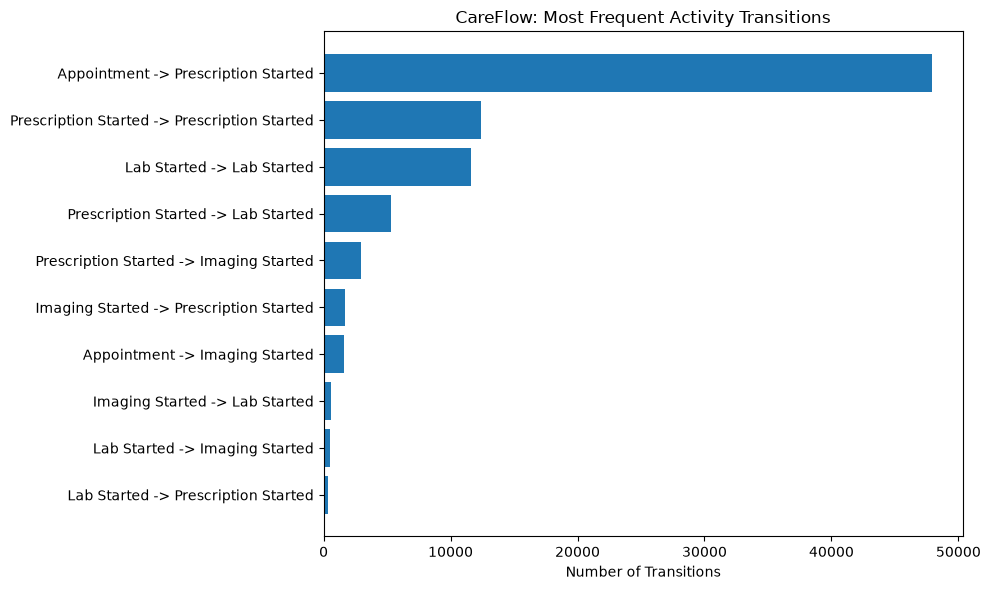

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Sort events chronologically within each appointment
ordered_events = event_log_clean.sort_values(
    ["case_id", "timestamp", "activity"]
)

# Count transitions between consecutive activities
transitions = Counter()

for case_id, group in ordered_events.groupby("case_id"):
    activities = group["activity"].tolist()

    for i in range(len(activities) - 1):
        transitions[(activities[i], activities[i + 1])] += 1

# Display the 10 most frequent transitions
top_transitions = transitions.most_common(10)

transition_df = pd.DataFrame(
    [
        {
            "From Activity": source,
            "To Activity": target,
            "Count": count
        }
        for (source, target), count in top_transitions
    ]
)

display(transition_df)

# Plot the transition counts
if not transition_df.empty:
    labels = (
        transition_df["From Activity"]
        + " -> "
        + transition_df["To Activity"]
    )

    plt.figure(figsize=(10, 6))
    plt.barh(labels[::-1], transition_df["Count"][::-1])
    plt.xlabel("Number of Transitions")
    plt.title("CareFlow: Most Frequent Activity Transitions")
    plt.tight_layout()
    plt.show()


In [17]:

# Save the transition table for later use
transition_df.to_csv("careflow_top_transitions.csv", index=False)

# Create a short project summary
summary = """
# CareFlow: Initial Process Mining Results

## Dataset
- Source: HospitalOPD dataset from Mendeley Data
- Original records: 62,422
- Original columns: 25
- Working columns after removing one empty column: 24
- Unique appointment IDs: 49,912

## Data quality checks
- No completely duplicated rows were detected.
- The Unnamed: 2 column was completely empty and removed from the working copy.
- Some service timestamps were missing.
- Some laboratory and imaging timestamps occurred before the recorded appointment start.

## Initial process mining
- An initial event log was created from appointment, prescription, laboratory,
  imaging, and pharmacy start timestamps.
- The most frequent observed transition was Appointment -> Prescription Started.
- Repeated activity transitions require further validation before clinical interpretation.

## Next steps
- Investigate repeated service records and timestamp ordering.
- Validate appointment-level event sequences.
- Develop a process map and dashboard after data validation.
"""

with open("careflow_analysis_notes.md", "w", encoding="utf-8") as f:
    f.write(summary)

print("Saved careflow_top_transitions.csv")
print("Saved careflow_analysis_notes.md")


Saved careflow_top_transitions.csv
Saved careflow_analysis_notes.md
